## Create a simple search engine with your own photos

> 1. Write a function that uses a CLIP model to embed all of your photos and saves the resulting vectors

> 2. Write a function that takes a search query(text or image), embeds it, then finds the most similar photo embeddings and displays the photos

> 3. YOU can manually implement the similarity search algorithm or a use a dedicated library such as the FAISS library or even a full-blown vector database.


In [137]:
import torch
from transformers import (
    CLIPTokenizer,
    CLIPImageProcessor,
    AutoModelForZeroShotImageClassification,
)
from PIL import Image
from os import listdir

In [22]:
device = "mps"

In [139]:
listdir("Imagini")

['wp1942214-2362608388.jpg',
 'DSCN2939.JPG',
 'photo_11_2026-07-20_09-42-46(1).jpg',
 'photo_5_2026-07-20_09-42-30.jpg',
 'wp1942063-the-wire-wallpapers.jpg']

In [9]:
def load_images(path):
    images_list = listdir(path)
    loaded_images = []
    for image in images_list:
        loaded_image = Image.open(path + image)
        loaded_images.append(loaded_image)
    return loaded_images

In [17]:
images = load_images("Imagini/")

In [65]:
images

[<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=4608x3456>,
 <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1280x721>,
 <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1280x720>,
 <PIL.JpegImagePlugin.JpegImageFile image mode=CMYK size=2592x1773>]

In [19]:
def as_tensor(out):
    return out if torch.is_tensor(out) else out.pooler_output

In [ ]:
model_id = "openai/clip-vit-base-patch32"
model = AutoModelForZeroShotImageClassification.from_pretrained(
    model_id, device_map="mps"
)
image_processor = CLIPImageProcessor.from_pretrained(model_id)
text_tokenizer = CLIPTokenizer.from_pretrained(model_id)
data_base = {"image_embedding": None, "image": images}


# If you have too many images you would get a Out of Memory Error
def embed_images(photos, model, image_processor):
    # print(images)
    photos_processed = image_processor(images=photos, return_tensors="pt").to(device)
    ##print(photos_processed)
    embedded_images = as_tensor(model.get_image_features(**photos_processed.to(device)))
    ##print(embedded_images.shape)
    # Normalize the images
    embedded_images /= embedded_images.norm(dim=-1, keepdim=True)
    ##print(embedded_images.shape)
    if data_base["image_embedding"] is None:
        data_base["image_embedding"] = embedded_images
    else:
        data_base["image_embedding"] = torch.cat(
            [data_base["image_embedding"], embedded_images], dim=0
        )


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [120]:
data_base["image_embedding"] is None

True

In [121]:
embed_images(images, model, image_processor)
data_base["image_embedding"].shape

torch.Size([4, 512])

In [132]:
def search_query(model, image_processor, text_tokenizer, text="", image=None):
    if image is not None:
        processed_photo = image_processor(
            images=image,
            return_tensors="pt",
        ).to(device)
        embedded_images = as_tensor(
            model.get_image_features(**processed_photo.to(device))
        )
        embedded_images /= embedded_images.norm(dim=-1, keepdim=True)
        similarities = embedded_images @ data_base["image_embedding"].T
        return data_base["image"][similarities.argmax(dim=-1)]
    if text != "":
        processed_text = text_tokenizer(
            text=text, return_tensors="pt", padding=True
        ).to(device)
        embedded_text = as_tensor(model.get_text_features(**processed_text.to(device)))
        embedded_text /= embedded_text.norm(dim=-1, keepdim=True)
        # print(embedded_text.shape)
        # print(data_base['image_embedding'].shape)
        similarities = embedded_text @ data_base["image_embedding"].T
        return data_base["image"][similarities.argmax(dim=-1)]
    return None


Trying text and image, similarity


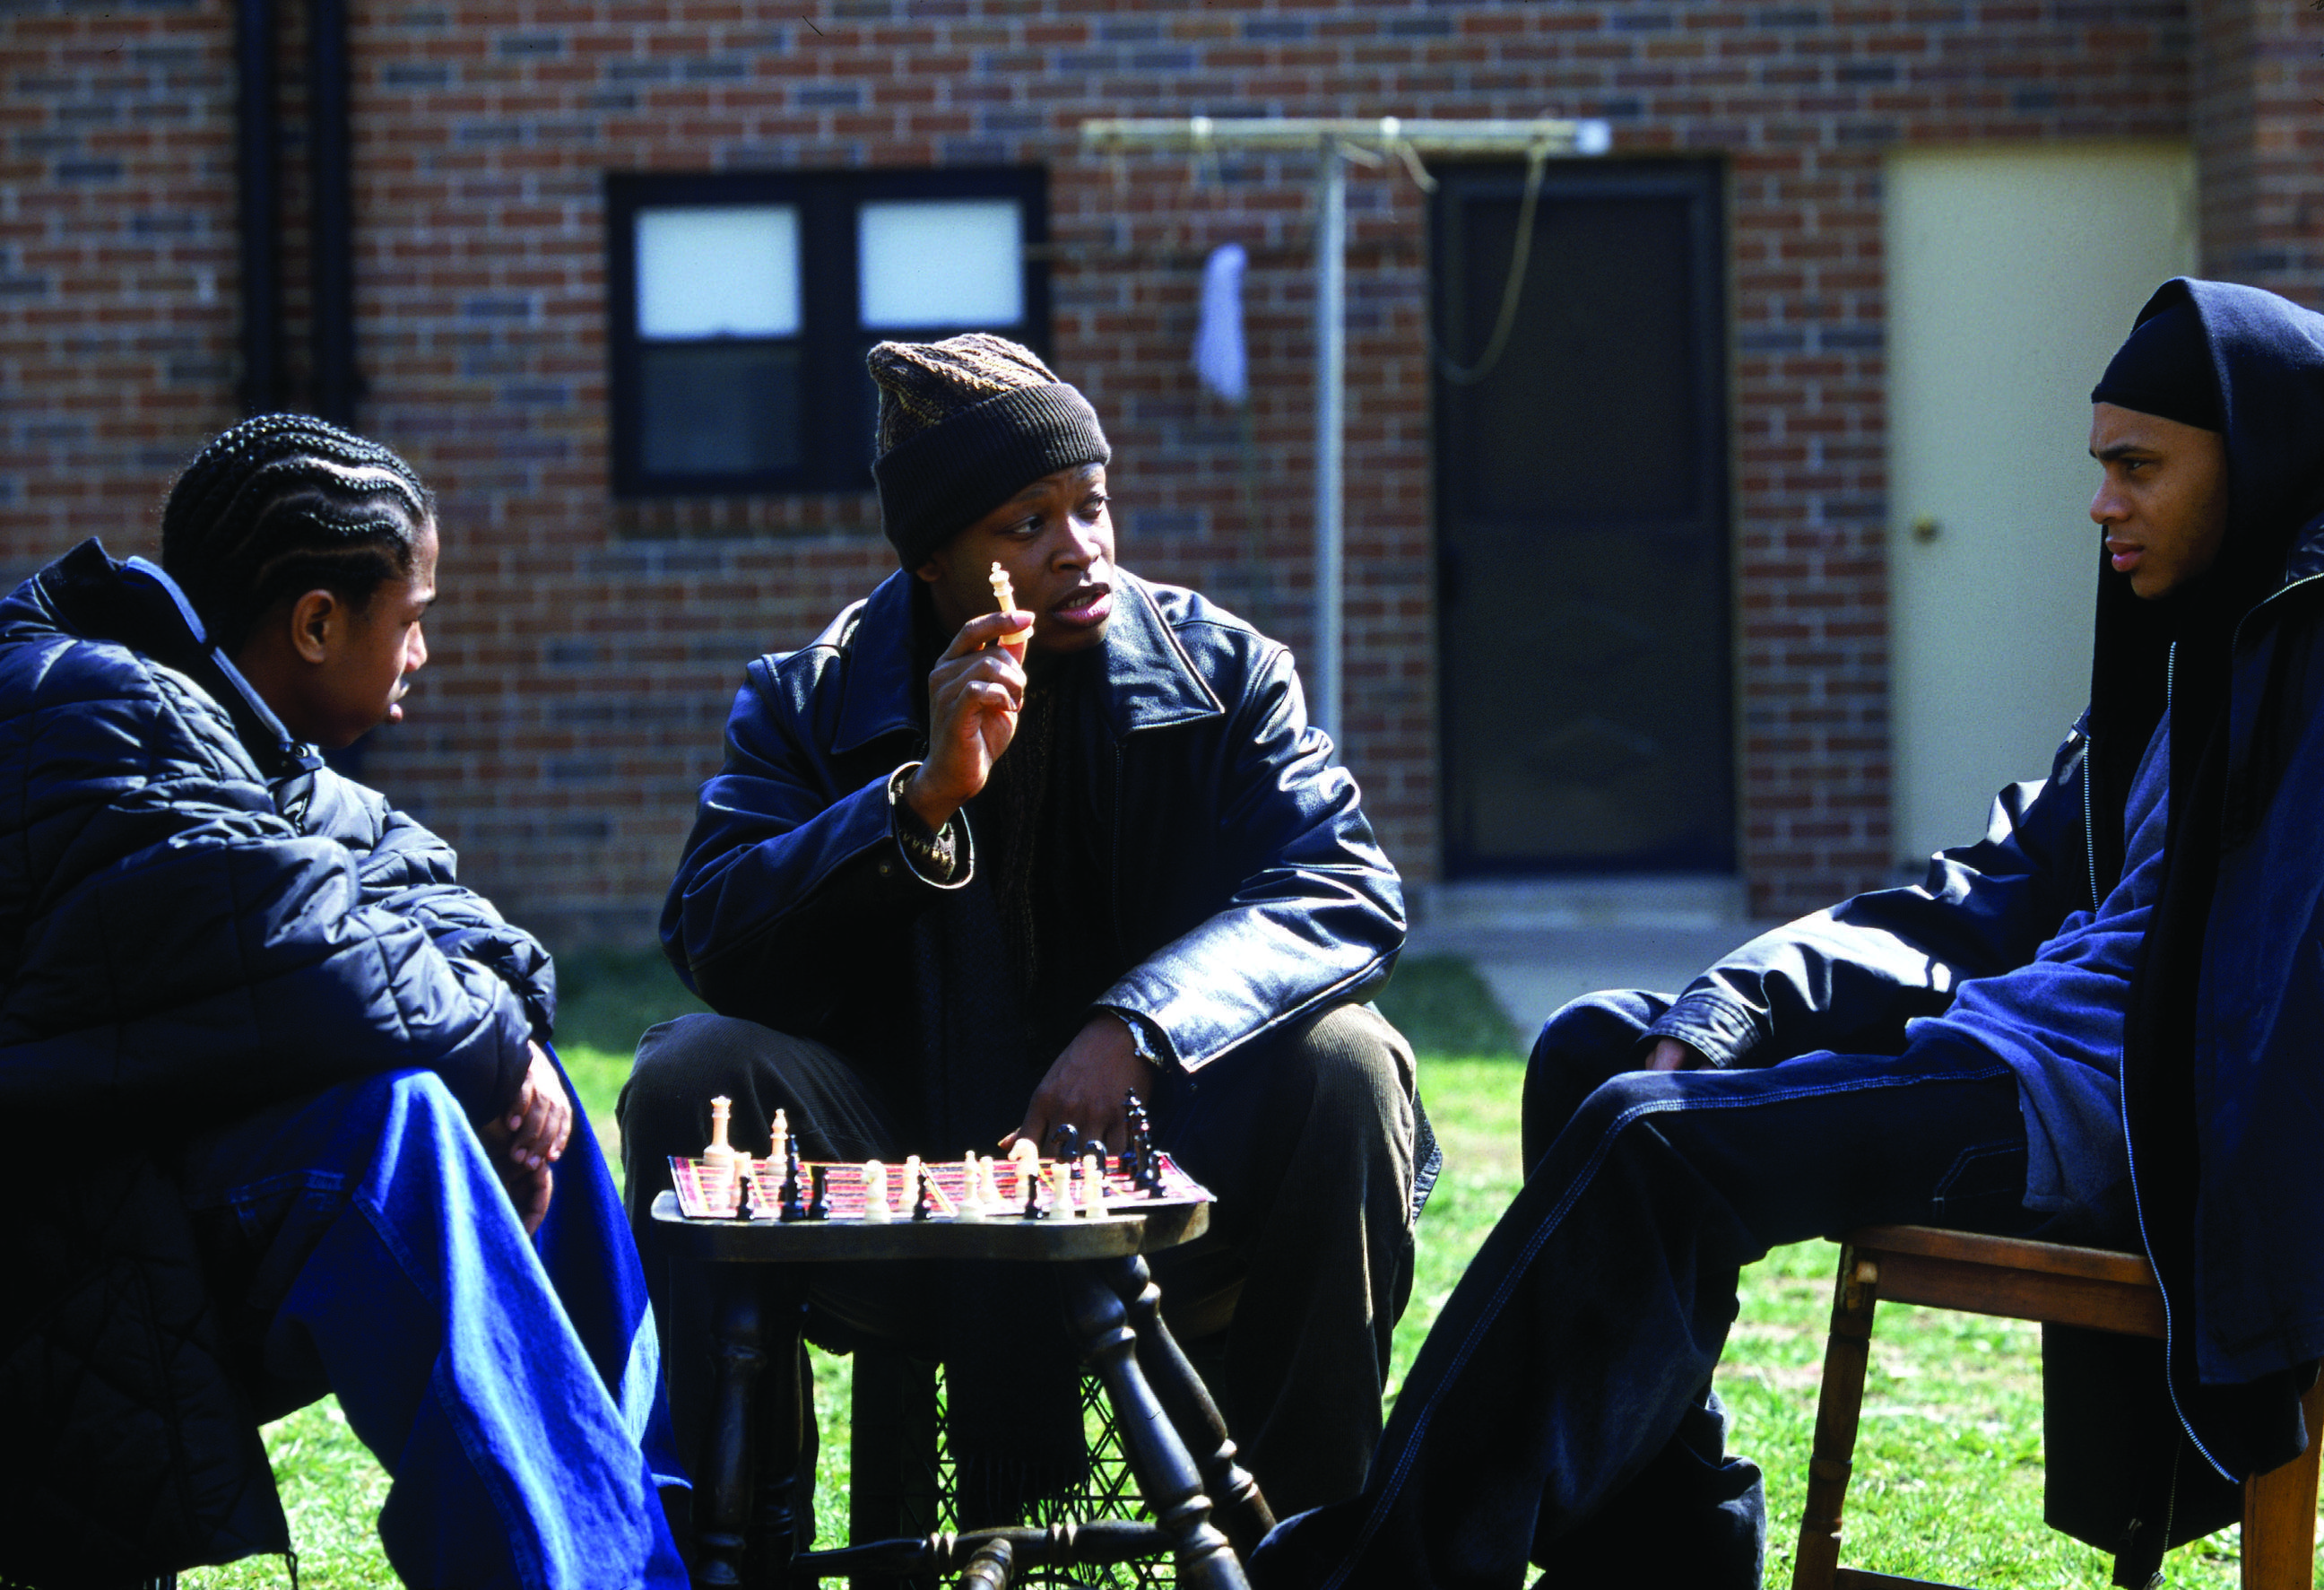

In [ ]:
search_query(
    model=model,
    image_processor=image_processor,
    text_tokenizer=text_tokenizer,
    text="a photo with guys sitting on chairs",
)

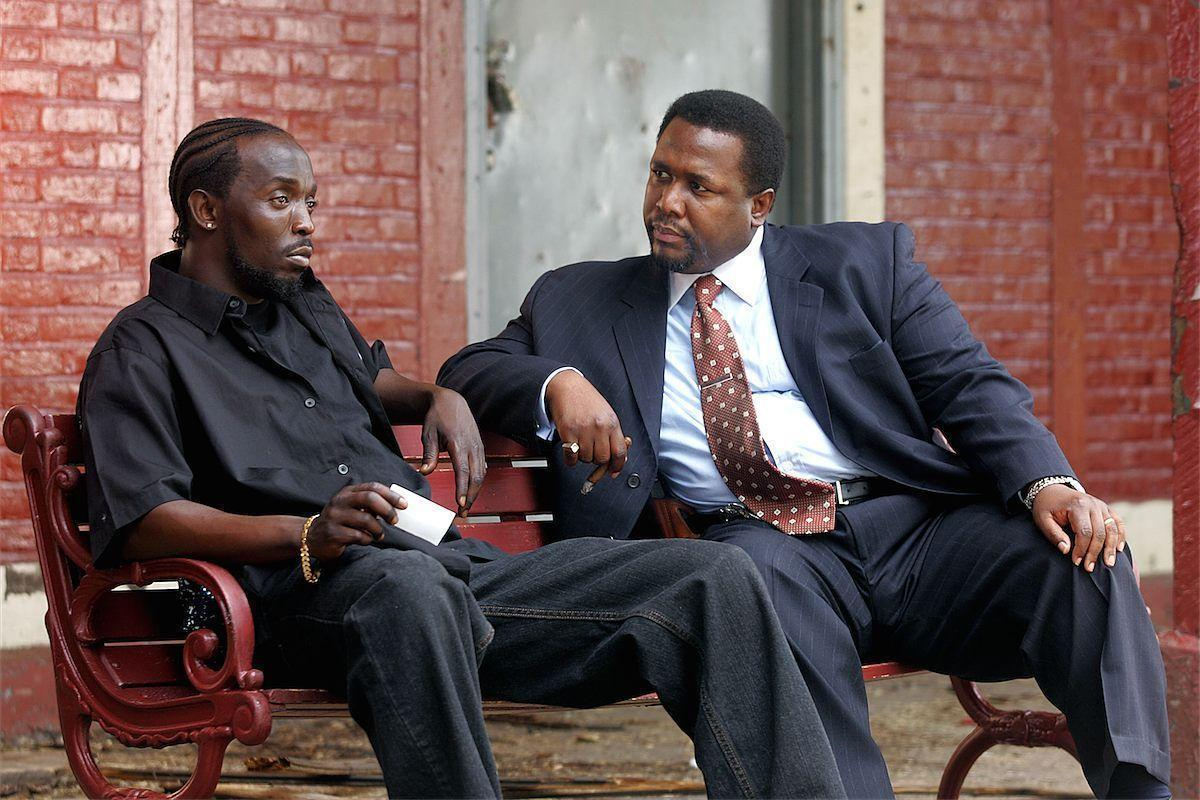

In [135]:
test_image = Image.open("Imagini/wp1942214-2362608388.jpg")
test_image

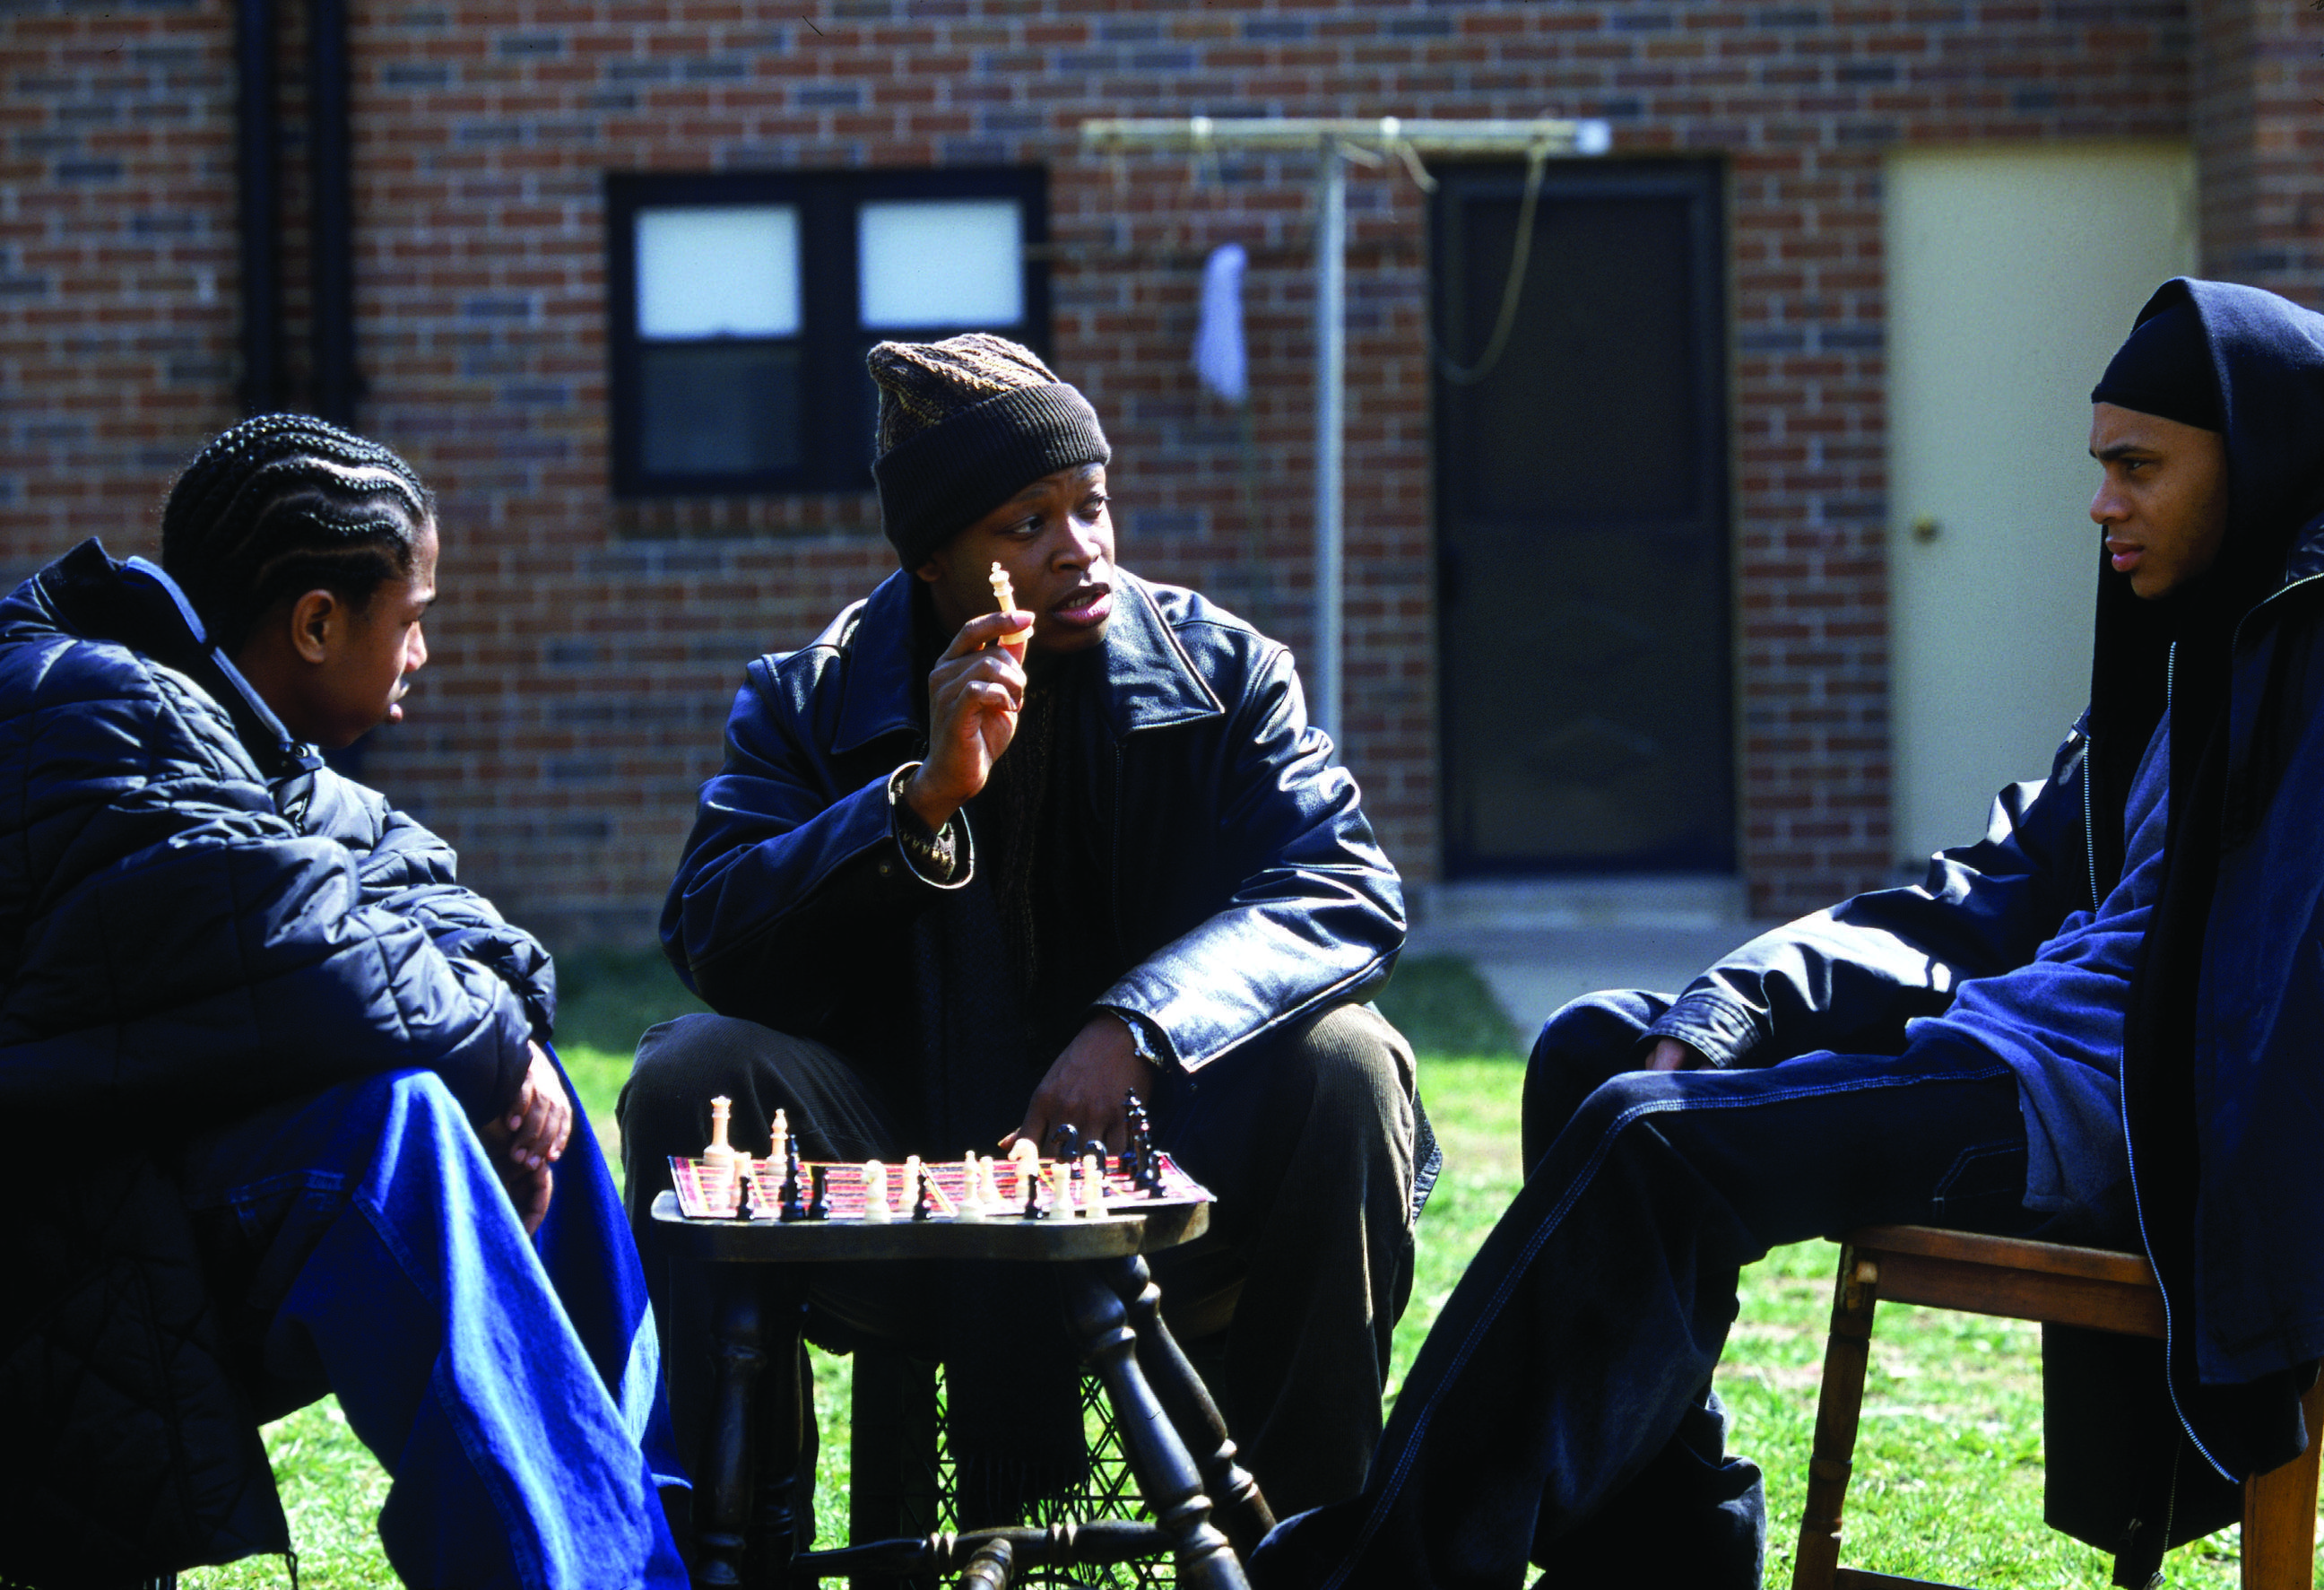

In [133]:
test_image = Image.open("Imagini/wp1942214-2362608388.jpg")
search_query(model, image_processor, text_tokenizer, image=test_image)